In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [95]:
df = pd.read_csv('social_media_engagement_5000.csv')

In [96]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [97]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [98]:
df['posted_at'] = pd.to_datetime
print(df)

      user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  Female     Brazil   496713     image       fitness   
1       10860  33.0    Male     Brazil   157326      reel          food   
2       86820  32.0  Female         UK   109864      text          food   
3       64886  51.0   Other     France   848877      text       fitness   
4       16265  34.0   Other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count  \
0      7011.0     354.0  1157.

In [99]:
missing_values = df.isnull().sum()
print(missing_values)


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [100]:
# Fill numerical missing values with median
df['age'] = df['age'].fillna(df['age'].median())
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())

# Fill categorical missing values with mode
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

In [101]:
missing_values = df.isnull().sum()
print(missing_values)

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [102]:
duplicate_count = df.duplicated().sum()
print(duplicate_count)

0


In [103]:
categorical_columns = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for column in categorical_columns:
    df[column] = df[column].astype(str).str.strip().str.lower()

print(df[categorical_columns].head())

   gender country post_type post_category device_type sentiment
0  female  brazil     image       fitness      mobile  negative
1    male  brazil      reel          food      mobile  negative
2  female      uk      text          food      tablet  positive
3   other  france      text       fitness      mobile  negative
4   other      uk     image       fitness      mobile  negative


In [104]:
print("Negative likes:", (df['likes'] < 0).sum())
print("Negative comments:", (df['comments'] < 0).sum())
print("Negative shares:", (df['shares'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


In [105]:
likes_array = np.array(df['likes'])

print("First 10 likes:")
print(likes_array[:10])

print("Total likes:", np.sum(likes_array))
print("Average likes:", np.mean(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Minimum likes:", np.min(likes_array))

First 10 likes:
[ 7011.  11750.   4862.   5350.  12682.  12535.  11703.   9611.  10105.5
 14106. ]
Total likes: 50534987.0
Average likes: 10106.9974
Maximum likes: 19998.0
Minimum likes: 10.0


In [106]:
def count_hashtags(text):
    hashtags = text.split()
    return sum(1 for word in hashtags if word.startswith('#'))

df['hashtag_count'] = df['hashtags'].apply(count_hashtags)

df[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [107]:
df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

df[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [108]:
print(df.shape)

print(df.columns.tolist())

print(df.head())

print(df.tail())

print(df.dtypes)

df.info()

(5000, 21)
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count', 'engagement_score']
   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  brazil   157326      reel          food  11750.0   
2    86820  32.0  female      uk   109864      text          food   4862.0   
3    64886  51.0   other  france   848877      text       fitness   5350.0   
4    16265  34.0   other      uk   449706     image       fitness  12682.0   

   comments  shares  ...  impression_count  \
0     354.0  1157.0  ...             44650   
1    2606.0  1807.0  ...             80216   
2     344.0   955.0  ...             44858   
3    1083.0  1049.0  ...             70455  

In [109]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count,engagement_score
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,393698.224800,0.964356,1.998600,12611.94780
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,230927.884535,5.318029,0.812853,5782.05846
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,87.000000,0.006363,1.000000,193.00000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,194480.000000,0.145781,1.000000,7807.00000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,388982.000000,0.253896,2.000000,12551.75000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,589744.250000,0.504794,3.000000,17478.25000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,799533.000000,191.504348,3.000000,24680.00000


In [110]:
print(df['gender'].value_counts())

gender
male      1849
other     1581
female    1570
Name: count, dtype: int64


In [111]:
print(df['post_type'].value_counts())
print(df['post_category'].value_counts())
print(df['country'].value_counts())
print(df['sentiment'].value_counts())
print(df['device_type'].value_counts())

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64


In [112]:
print(df['post_type'].unique())
print(df['post_type'].nunique())
print(df['post_category'].unique())
print(df['post_category'].nunique())

<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
4
<StringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str
8


In [113]:
numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate',
    'engagement_score'
]

correlation_matrix = df[numeric_columns].corr()

print(correlation_matrix.round(2))


                   age  likes  comments  shares  watch_time_sec  \
age               1.00  -0.04     -0.01    0.01            0.01   
likes            -0.04   1.00     -0.02    0.00            0.01   
comments         -0.01  -0.02      1.00    0.01           -0.02   
shares            0.01   0.00      0.01    1.00            0.01   
watch_time_sec    0.01   0.01     -0.02    0.01            1.00   
impression_count  0.01   0.01     -0.01   -0.01           -0.00   
follower_count   -0.02  -0.02     -0.01   -0.01            0.00   
engagement_rate   0.01   0.09      0.00    0.02           -0.00   
engagement_score -0.04   0.98      0.13    0.10            0.01   

                  impression_count  follower_count  engagement_rate  \
age                           0.01           -0.02             0.01   
likes                         0.01           -0.02             0.09   
comments                     -0.01           -0.01             0.00   
shares                       -0.01           

In [114]:
avg_likes_post_type = df.groupby('post_type')['likes'].mean().sort_values(ascending=False)

print(avg_likes_post_type)

post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64


In [115]:
avg_engagement_post_type = (
    df.groupby('post_type')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(avg_engagement_post_type)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64


In [116]:
country_engagement = (
    df.groupby('country')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(country_engagement)

country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64


In [117]:
sentiment_analysis = df.groupby('sentiment')[
    ['likes', 'comments', 'shares', 'engagement_rate']
].mean()

print(sentiment_analysis.round(3))

               likes  comments    shares  engagement_rate
sentiment                                                
negative   10208.097  1516.095  1007.307            1.038
neutral     9923.194  1528.404   996.565            0.991
positive   10180.062  1480.651  1005.087            0.920


In [118]:
#Task 5 — Statistical Analysis 
metrics = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

for column in metrics:

    print("\n", "=" * 50)
    print("Metric:", column)

    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode().iloc[0])
    print("Standard Deviation:", df[column].std())
    print("Variance:", df[column].var())





Metric: likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Standard Deviation: 5702.293017183877
Variance: 32516145.65382401

Metric: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Standard Deviation: 856.3933120458984
Variance: 733409.5049169434

Metric: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Standard Deviation: 570.8551999758852
Variance: 325875.65933950787

Metric: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916
Standard Deviation: 2308.0964590420845
Variance: 5327309.264242608

Metric: engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909
Standard Deviation: 5.31802922266154
Variance: 28.281434813082104

Metric: follower_count
Mean: 393698.2248
Median: 388982.0
Mode: 497502
Standard Deviation: 230927.88453461003
Variance: 53327687855.63019


In [119]:
df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

df[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


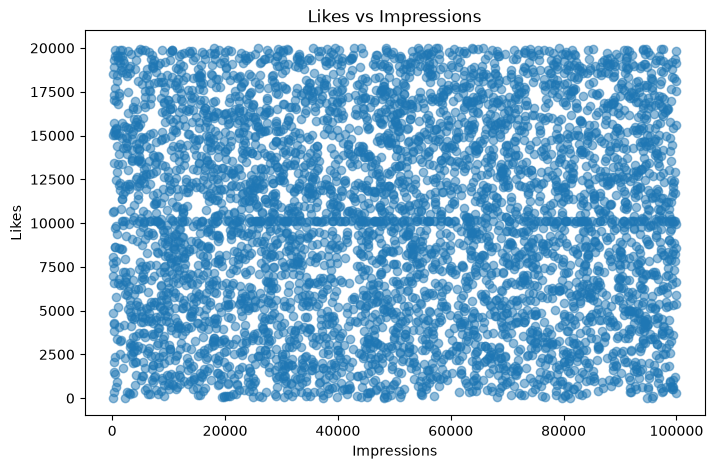

In [120]:
#Task 6 — Data Visualization
# likes vs impressions
plt.figure(figsize=(8, 5))

plt.scatter(
    df['impression_count'],
    df['likes'],
    alpha=0.5
)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.show()

In [121]:
# Convert posted_at to datetime
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    dayfirst=True,
    errors='coerce'
)

# Create date column
df['date'] = df['posted_at'].dt.date

# Check
print(df[['posted_at', 'date']].head())

  posted_at date
0       NaT  NaT
1       NaT  NaT
2       NaT  NaT
3       NaT  NaT
4       NaT  NaT


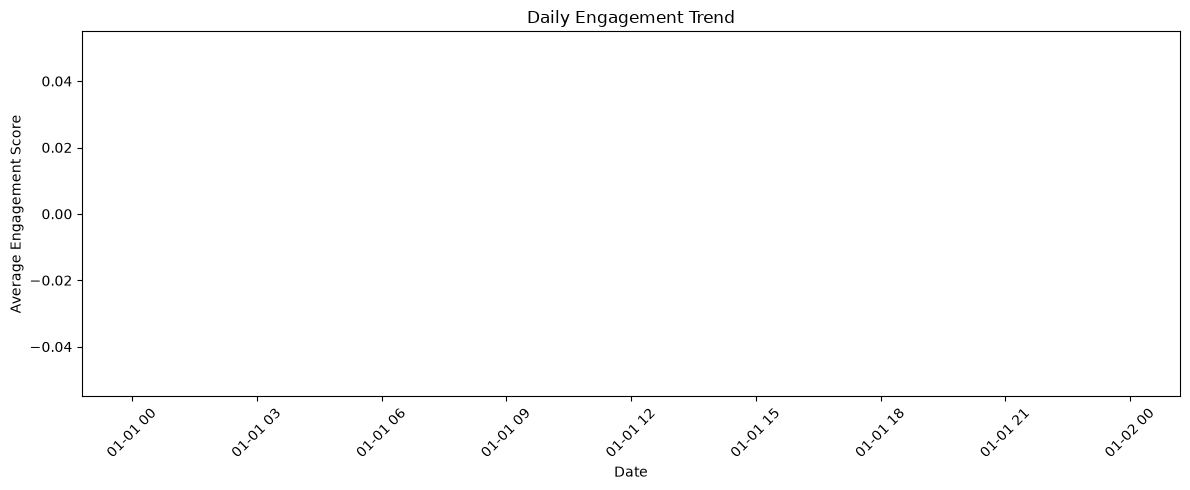

In [122]:
#posts by category
daily_engagement = (
    df.groupby('date')['engagement_score']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_engagement['date'],
    daily_engagement['engagement_score']
)

plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

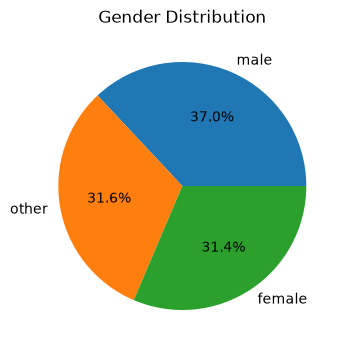

In [123]:
# gender distribution
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(4, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

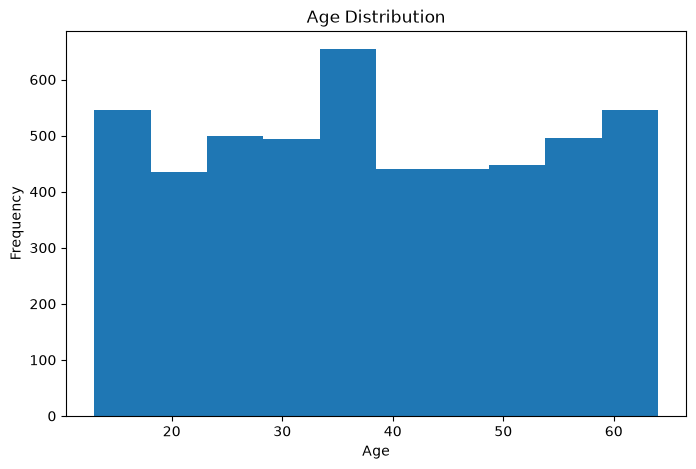

In [124]:
#Histogram: age
plt.figure(figsize=(8, 5))

plt.hist(
    df['age'],
    bins=10
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

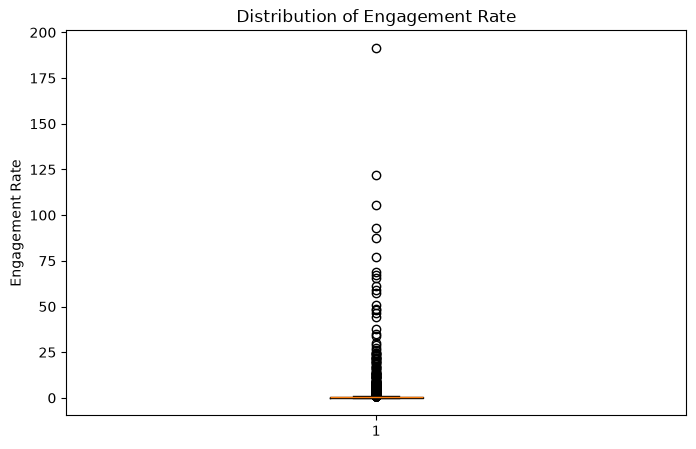

In [125]:
#Box: engagement rate
plt.figure(figsize=(8, 5))

plt.boxplot(df['engagement_rate'])

plt.title('Distribution of Engagement Rate')
plt.ylabel('Engagement Rate')

plt.show()

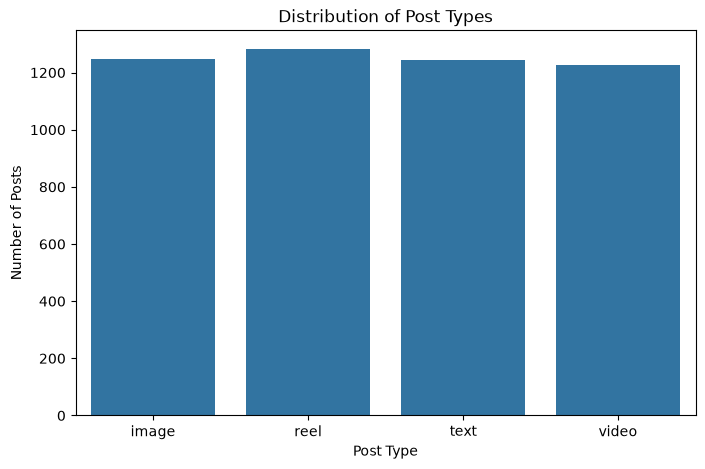

In [126]:
#Seaborn
#Count plot: post type

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='post_type'
)

plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')

plt.show()

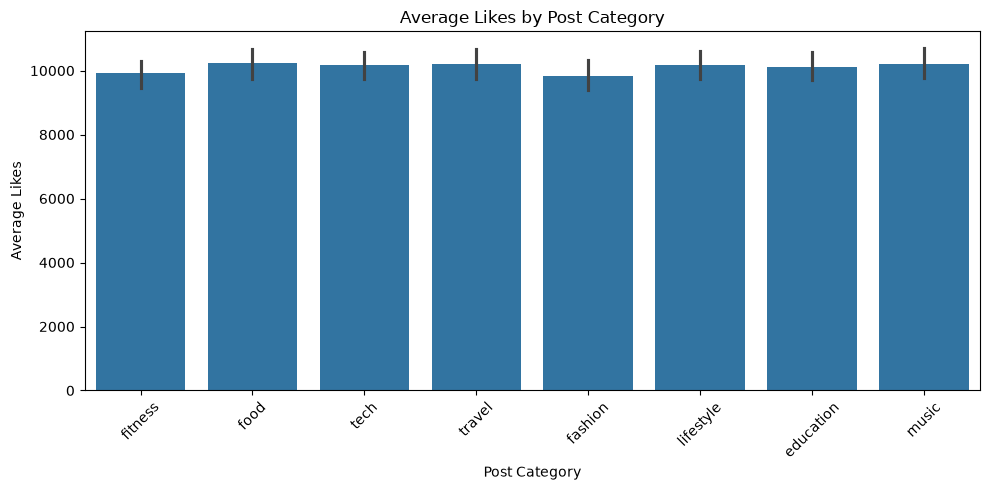

In [127]:
#Bar plot: avg likes by category
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    estimator='mean'
)

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


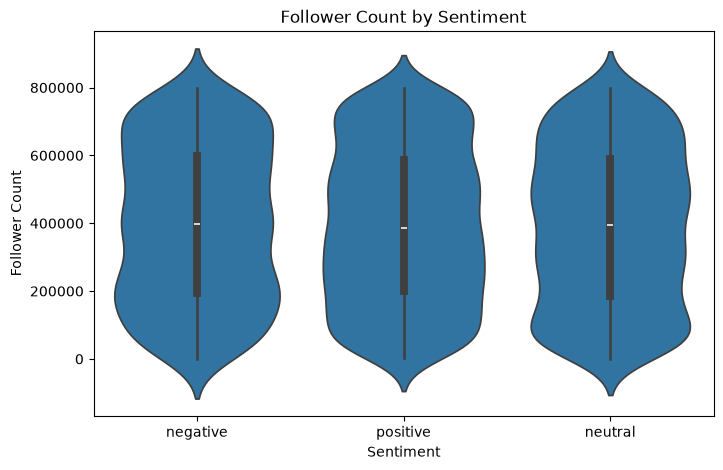

In [128]:
#Violin: followers vs sentiment
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Follower Count by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.show()

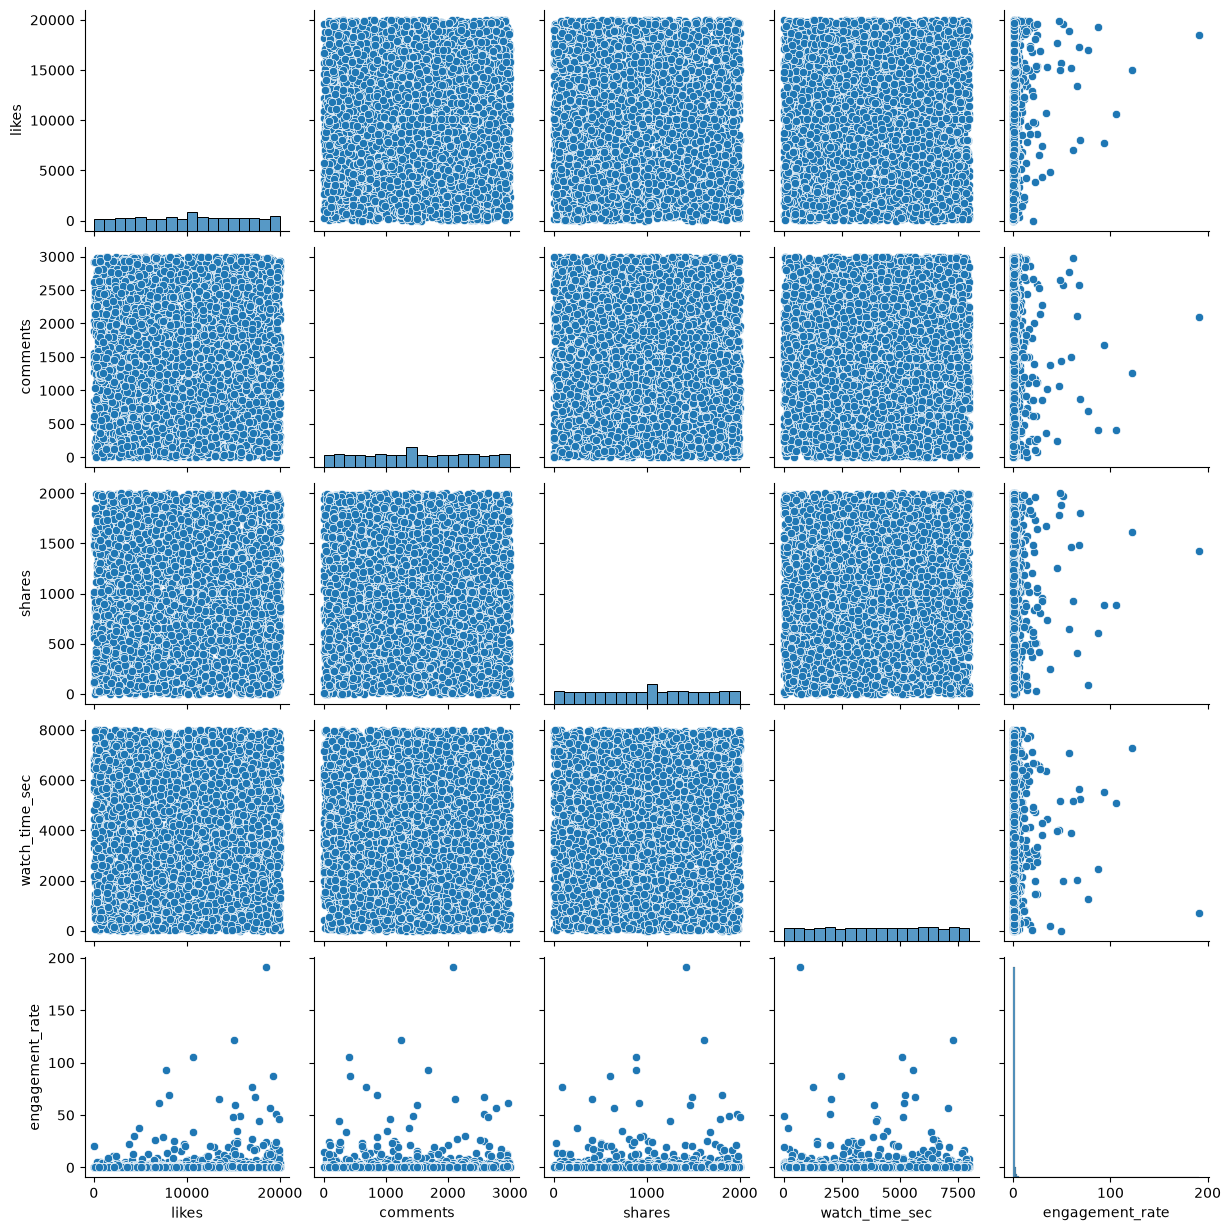

In [129]:
#Pair plot: numeric features
pair_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate'
]

sns.pairplot(df[pair_columns])

plt.show()

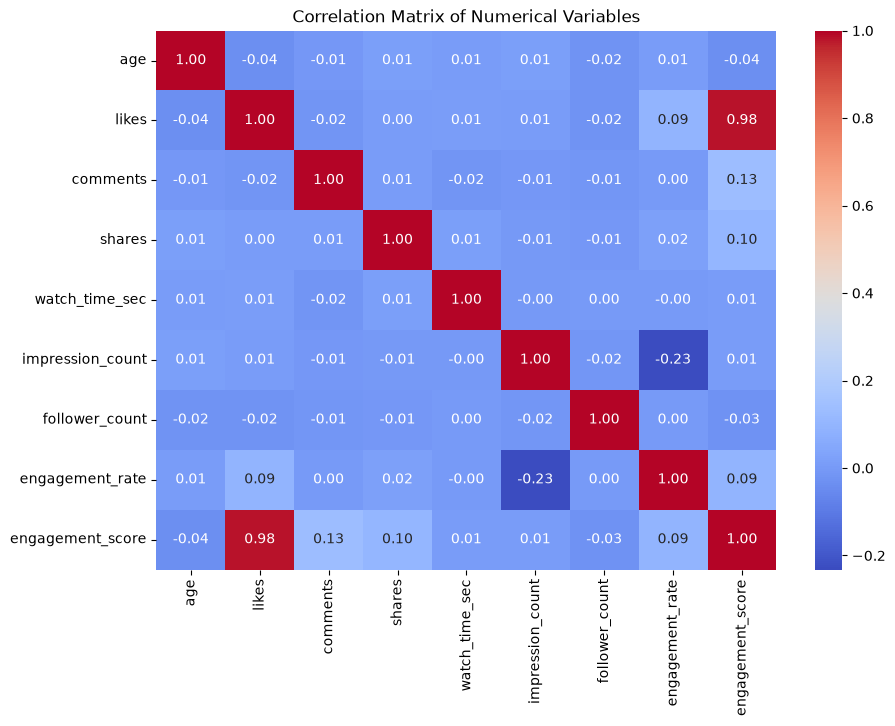

In [130]:
#Heatmap: correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Variables')

plt.show()

c:\Users\User1\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 72.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\User1\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 73.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\User1\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 72.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\User1\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 78.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(ms

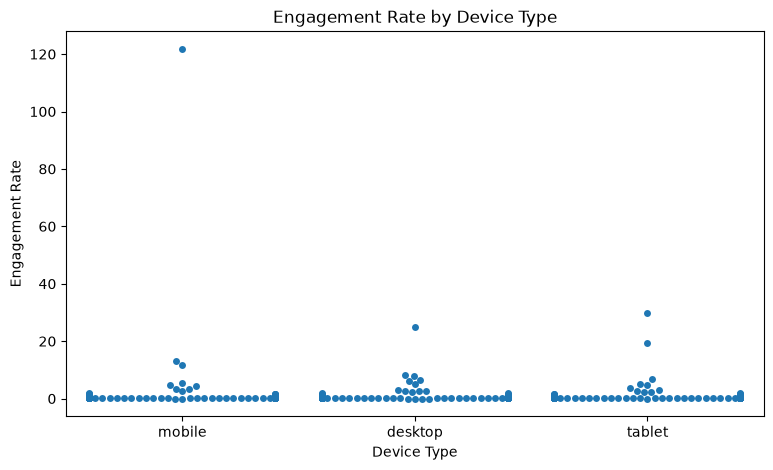

In [131]:
#Swarm plot: engagement vs device
sample_df = df.sample(
    n=500,
    random_state=42
)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_rate'
)

plt.title('Engagement Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')

plt.show()

In [143]:
#Plotly (Interactive)
category_engagement = (
    df.groupby('post_category')
    .agg(
        average_likes=('likes', 'mean'),
        average_engagement=('engagement_rate', 'mean')
    )
    .reset_index()
)

fig = px.bar(
    category_engagement,
    x='post_category',
    y='average_engagement',
    title='Average Engagement Rate by Content Category',
    hover_data=['average_likes']
)

fig.show(renderer="browser")

In [ ]:
# Which post types have highest engagement?
Video posts have the highest average engagement rate in this dataset.

In [ ]:
#Best-performing content category?
Food has the highest average engagement rate among the content categories.

In [ ]:
#Which countries have highest avg engagement rate? 
Brazil has the highest average engagement rate in the dataset, followed by Australia, France and UAE.

In [ ]:
#How age affects engagement
Engagement differs across age groups, with the 45-54 group showing the highest average engagement rate.

However, the relationship is not linear, so age alone does not explain engagement.

In [ ]:
#Performance difference for verified accounts
Verified accounts show a higher average engagement rate and slightly 
higher average watch time than non-verified accounts in this dataset.

In [ ]:
#Best time of day for impressions
The dataset contains date but no time-of-day information.
Therefore, the exact best posting hour cannot be determined.
Using the available date information, Tuesday has the highest average impressions by weekday.

In [ ]:
#Device type impact on watch time
Mobile has the highest average watch time.

In [ ]:
#Which sentiment performs best
Negative sentiment posts have the highest average engagement rate,
followed by neutral and positive posts.